# Leaf Classification Exercise Instructions

# Machine Learning and Pattern Recognition (TKO_3120)



This is the template for the image recognition exercise. <Br>
Some **general instructions**:
 - write a clear *report*, understandable for an unspecialized reader: define shortly the concepts and explain the phases you use
    - use the Markdown feature of the notebook for larger explanations
 - return your output as a working Jupyter notebook
 - name your file as MLPR26_exercise_surname_firstname.jpynb
 - write easily readable code with comments     
     - if you exploit some code from web, provide a reference
     - avoid redundant code! Exploit the relevent parts and modify the code for your purposes to produce only what you need
 - it is ok to discuss with a friend about the assignment. But it is not ok to copy someone's work. Everyone should submit their own implementation
 - Use of AI is prohibited

**Deadline 15th of March at 12:00**
- No extension granted, unless you have an extremely justified reason. In such case, ask for extension well in advance!
- Start now, do not leave it to the last minute. This exercise will need some labour!
- If you encounter problems
    - Google first
    - ask for help at the discussion area at Moodle
    - email svwelg@utu.fi

Grading

The exercise covers a part of the grading in this course. The course exam has 5 questions, 6 points of each. Exercise gives 6 points, i.e. the total score is 36 points.

From the template below, you can see how many exercise points can be acquired from each task. Exam points are given according to the table below:

9-10 exercise points: 1 points

11-12 exercise points: 2 points

13-14 exercise points: 3 points

15-16 exercise points: 4 points

17-18 exercise points: 5 points

19-20 exercise points: 6 points

To pass the exercise, you need at least 9 exercise points, distributed somewhat evenly into tasks (you can't just implement Introduction, Data preparation and Feature extraction and leave the left undone!)

# Introduction (1 p)

Write an introductory chapter for your report.

For example:

What is the purpose of this task?

What kind of data are used and where do they originate from?

Which machine learning methods are applied?<br>  
<br>

Dataset

The dataset consists of leaf images from three plant species:

Basil

Lemon

Chinar

Images are from Kaggel.

This project on machine learning and pattern recognition aims to solve a multi-class classification problem. In the scope of the project, 3 different kinds of leaves will be classified, Basil, Chinar and Lemon. The data consists of RGB images with 3 color channels and 256 quantization levels for each channel. The data is taken from Kaggle. To complete this project, the raw data will be received, they will be prepared for feature extraction (i.e. convert to greyscale, quantization etc.), then feature extraction techniques will be applied on the dataset and features will be visualized using several plotting techniques. Then, machine learning methods will be applied to the data to be able to classify the images using the extracted features. In this part, 3 main ML methods were used: Ridge Classifier, which is simply a linear model that works b applying linear regression. Random Forest, which is an ensemble method that uses multiple decision trees to classify the given sample. And finally, multi- layer- perceptron was used.

# Data Preparation (3 p)

Perform necessary data preparation steps:

Import all required packages in one cell

Read all images from the given folders

Convert images to grayscale when needed

Reduce grayscale quantization (e.g. to 8 gray levels) for texture analysis

Prepare data structures for feature extraction

In [1]:
#Importing Required Packages For the Whole Project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from skimage import io, img_as_float, color
from skimage.feature import graycomatrix, graycoprops
from skimage.feature import match_template
from skimage.transform import resize
from sklearn.decomposition import PCA

In [2]:
#Reading the Images
DATASET_PATH = os.path.join(".", "Dataset") #The dataset path


#Loads the data and creates a dictionary where keys are labels and values are lists of images
def load_data(datasetPath):
    print(f"Loading data paths:")
    dataPaths = dict()   #Keys are classes, values are lists of paths of images
    for elem in os.listdir(datasetPath):   #Go into each class folder
        path = os.path.join(datasetPath, elem) #Get folder path
        print(f"Walking into {path}")
        imagePaths = []
        for image in os.listdir(path):  #Go into each image path inside class folder
            imagePaths.append(os.path.join(path, image))    #Add image to path list
        dataPaths[elem] = imagePaths #Add list to dictionary
    #Go into directories and get images as actual image objects
    datasets = dict()   
    for label, paths in dataPaths.items():
        datasets[label] = []
        for image in paths:
            img = img_as_float(io.imread(image))
            datasets[label].append(img)
    return datasets

datasets = load_data(DATASET_PATH)

Loading data paths:
Walking into .\Dataset\Basil
Walking into .\Dataset\Chinar
Walking into .\Dataset\Lemon


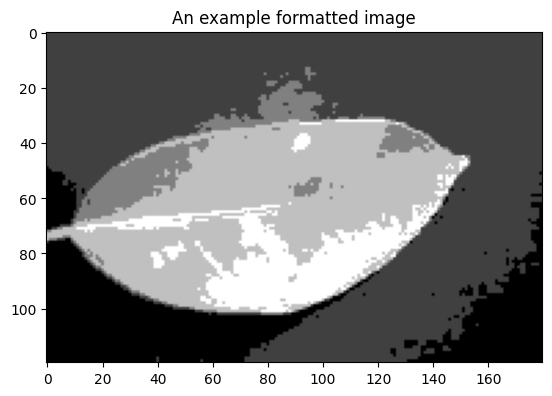

In [3]:
#Formatting the  data
#Converts images to grayscale in the whole dataset
def convertToGray(dataset):
    greyedImgs = dict()
    for label, imgs in dataset.items():
        greyedImgs[label] = list()
        for img in imgs:
            greyedImgs[label].append(color.rgb2gray(img))
    return greyedImgs

#Changes the quantization level of all images in dataset, assumes initial quantization of 256 levels
def changeQuantization(dataset, qLevel):
    for label, data in dataset.items():
        for idx in range(len(data)):
            img = data[idx] #Get original image
            img = np.array(img) #Convert to array
            img = np.floor(img * qLevel).astype(np.uint8)    #Apply new quantization level and convert to integer
            data[idx] = img #Update list
        dataset[label] = data   #Update the key
    return dataset

modifiedDatasets = convertToGray(datasets)  #Convert to greyscale
modifiedDatasets = changeQuantization(modifiedDatasets,8)   #Reduce quantization to 8 gray levels
#Testing to see some images
for label, images in modifiedDatasets.items():
    for img in images:
        plt.imshow(img, cmap='gray')
        plt.title("An example formatted image")

# Feature Extraction

**First order texture measures (6 features)**

Calculate the following color features for each image **(1 p)**:

Mean value of each RGB channel

Variance of each RGB channel<br>
<br>

**Second order texture measures**

Gray-Level Co-Occurrence Matrix (GLCM) features **(2 p)**

For each image:

Convert the image to grayscale

Quantize the grayscale image

Compute GLCM-based texture features

Extract the correlation feature

Explain briefly what the correlation feature measures<br>
<br>


**Additional image-based features**

Extract template-matching features:**(2 p)**

Select one representative template image per class

Compute normalized template matching scores

Use the maximum response as a feature

Explain why template matching may help classification.


### First Order Texture Measures 

In [4]:
#Extracts first level features for a singular image
def getfeaturesDict(img):
    #Get each color channel
    R = img[..., 0]
    G = img[..., 1]
    B = img[..., 2]

    #Get means of each color channel
    meanR = np.mean(R)
    meanG = np.mean(G)
    meanB = np.mean(B)

    #Get variances of each color channel
    varR = np.var(R)
    varG = np.var(G)
    varB = np.var(B)

    return {
        "meanR": meanR,
        "meanG": meanG,
        "meanB": meanB,
        "varR": varR,
        "varG": varG,
        "varB": varB,
    }

#Extracts a single feature and returns as np array
def extractFeature(featureDataset, feature, oneClass = "no"):
    listToStore = list()
    if oneClass != "no":
        images = featureDataset[oneClass]
        for features in images:
            listToStore.append(features[feature])
    else:
        for label, images in featureDataset.items():
            for features in images:
                listToStore.append(features[feature])
    return np.array(listToStore)

#Calculate first order measures for each image
featuresDict = dict()
for label, images in datasets.items():
    temp = list()
    for img in images:
        features = getfeaturesDict(img)
        features["class"] = label   #Add the label to the features as well
        temp.append(features)
    featuresDict[label] = np.array(temp)

### Second Order Texture Measures

In [5]:
#The distances and angles for which to calculate GLCM matrix
distancesGLCM = [1,2,3]
anglesGLCM = [0,45,90]
#Go through the greyscale images and extract their correlation features
for label, images in modifiedDatasets.items():
    temp = list()
    idx  = 0
    for img in images:
        glcm = graycomatrix(image=img,levels=8,distances=distancesGLCM,angles=anglesGLCM,symmetric=True)   #Compute GLCM for 3 distances and 3 angle values
        corr = graycoprops(glcm,prop='correlation')
        featuresDict[label][idx]["correlation"] = corr
        idx += 1

Correlation feature is a second order texture measure for greyscale images that is calculated by utilizing the GLCM. It is calculated by summing up the normalized elements of a GLCM for a given distance andd angle (in a similar fashion for calculating pearson correlation for a given pair of gray levels.). In short, it measures how smooth an image is. If the correlation is close to 1, it means that we are much more likely to find a gray level j that is close or the same as another gray level i in an image. This would imply that the image is smooth and there isn't much steep changes in intensity levels in the image. Similarly, a correlation of 0 would imply there is no correlation between the two given gray levels in the image, meaning that the gray levels are quite random in the image. And finally, a negative correlation implies that the gray levels are inversely proportional to each other, meaning that you are much more likely to find stark contrasts in the image.

### Template Matching Features

In [6]:
TEMPLATE_SIZE = (50, 50)

#Create a dictionary to store the representative templates for each class
class_templates = {}

for label in modifiedDatasets.keys():
    #Take the first image of each class as the representative template
    raw_template = modifiedDatasets[label][0]
    #Resize to a standard small size to ensure it fits inside all other images
    class_templates[label] = resize(raw_template, TEMPLATE_SIZE, anti_aliasing=True)

#Go through each image and compute max correlation score against all three templates
for label, images_list in modifiedDatasets.items():
    for idx, img in enumerate(images_list):
        #Test each image against all 3 class templates
        for temp_label, template in class_templates.items():
            #Compute normalized cross-correlation between image and template
            result = match_template(img, template)
            #Use the maximum response as the feature
            max_score = np.max(result)
            #Add the score to featuresDict under the matching template label
            featuresDict[label][idx][f"tmatch{temp_label.capitalize()}"] = max_score

### Explain why temp matching is important here

# Feature Relationships

Visualize and analyze the relationships between extracted features.<br>
<br>

**Pairplot (1 p)**

Create a pairplot of the features

Which feature pairs show approximately linear dependence?<br>
<br>

**Histograms (1 p)**

Plot a histogram for each standardized feature

Plot all image classes in the same figure using different colors

Which features seem to have discriminative power?<br>
<br>

**PCA (1 p)**

Perform Principal Component Analysis

Plot the image classes using different colors

Can you see clusters?

What does PCA suggest about classification performance?

### Pairplots

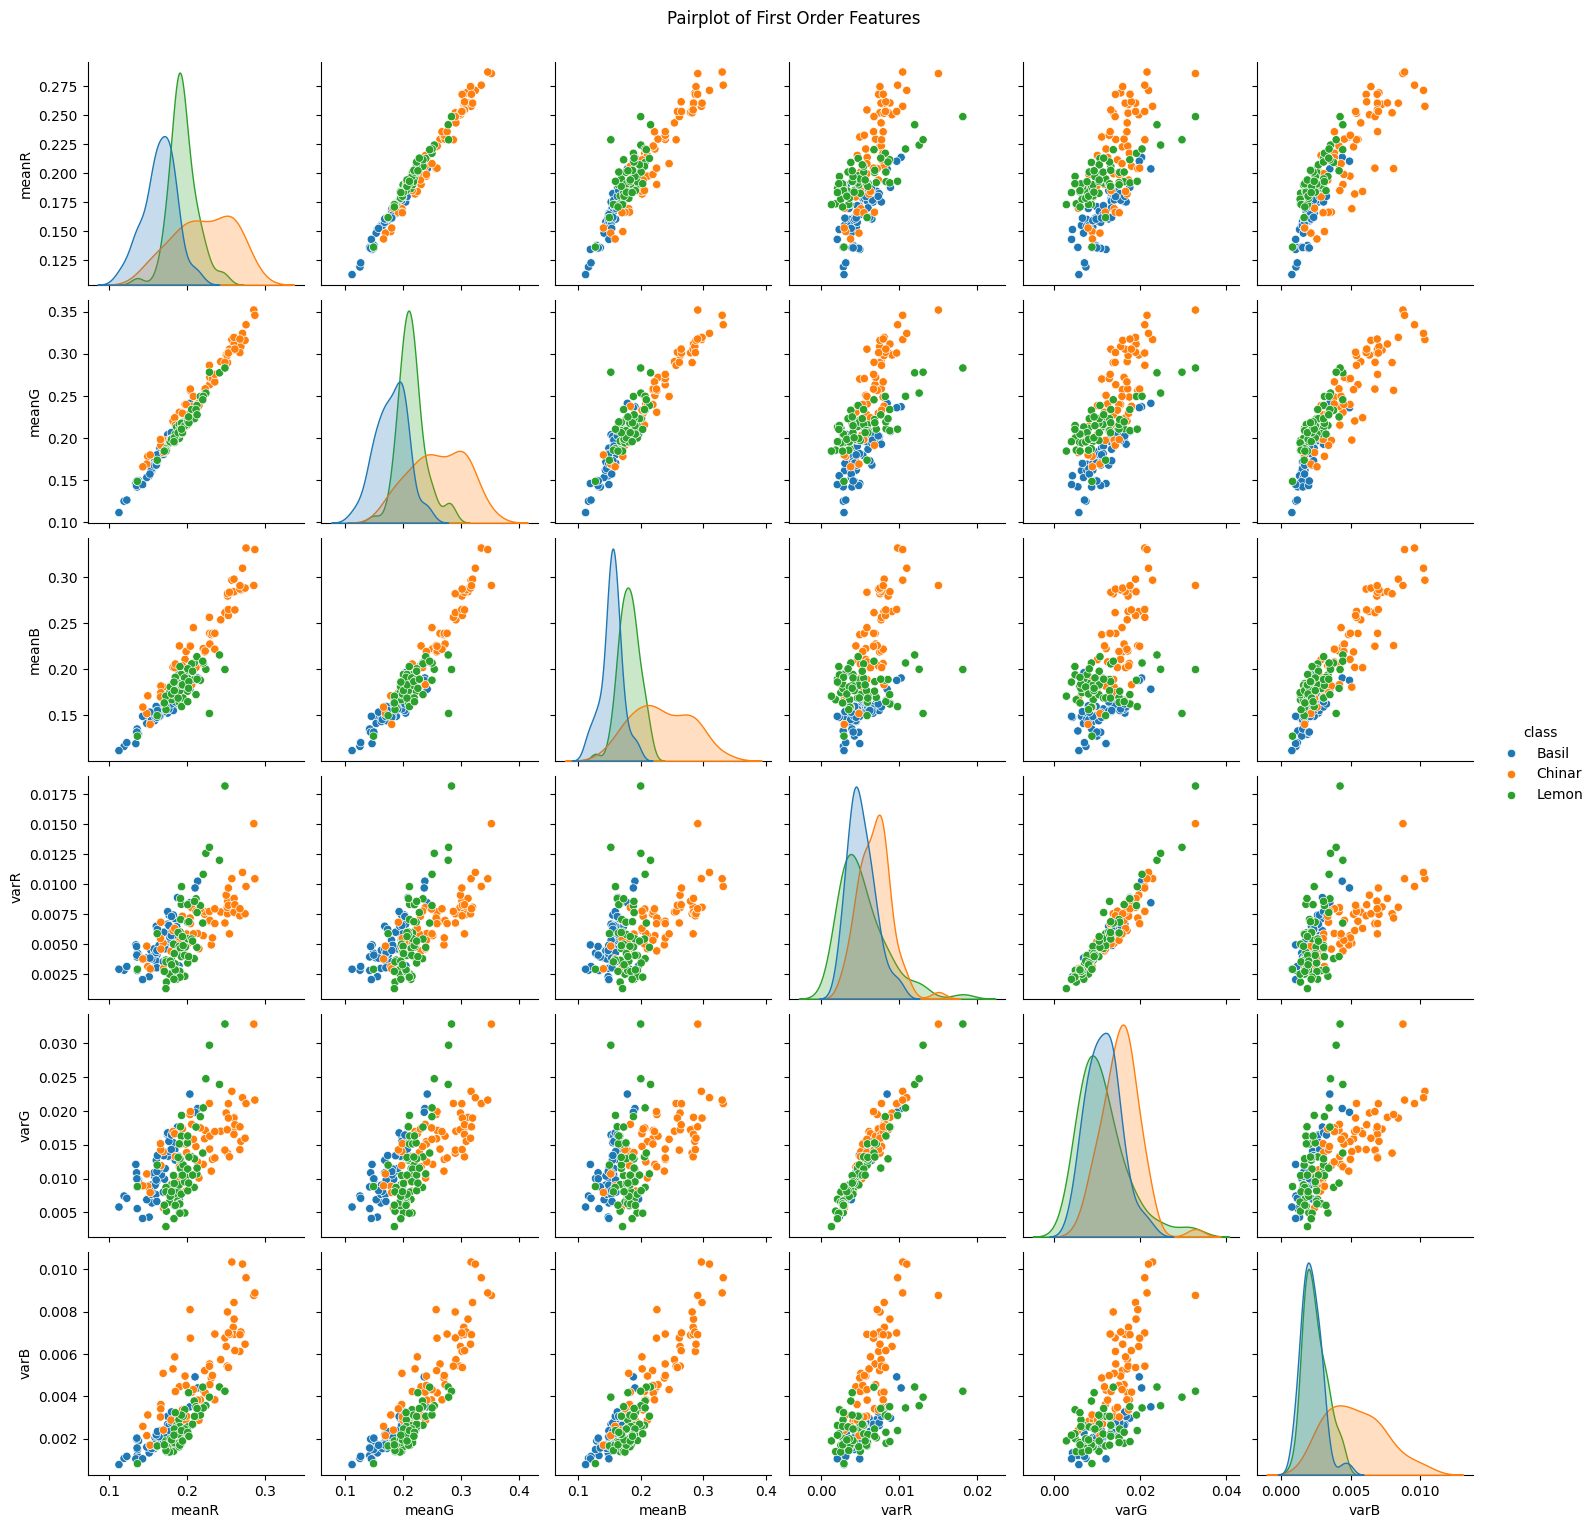

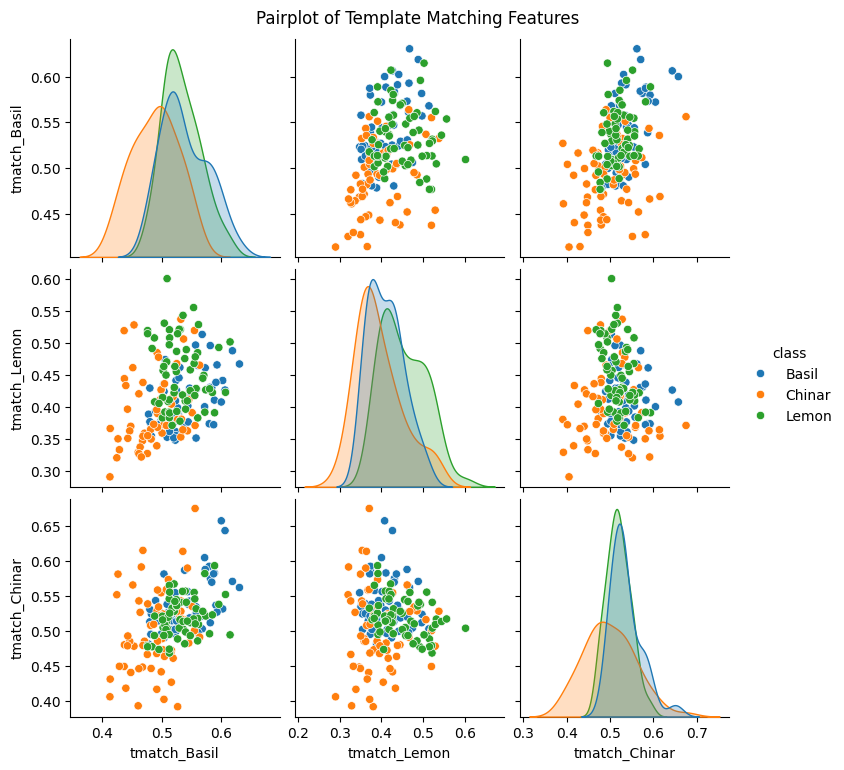

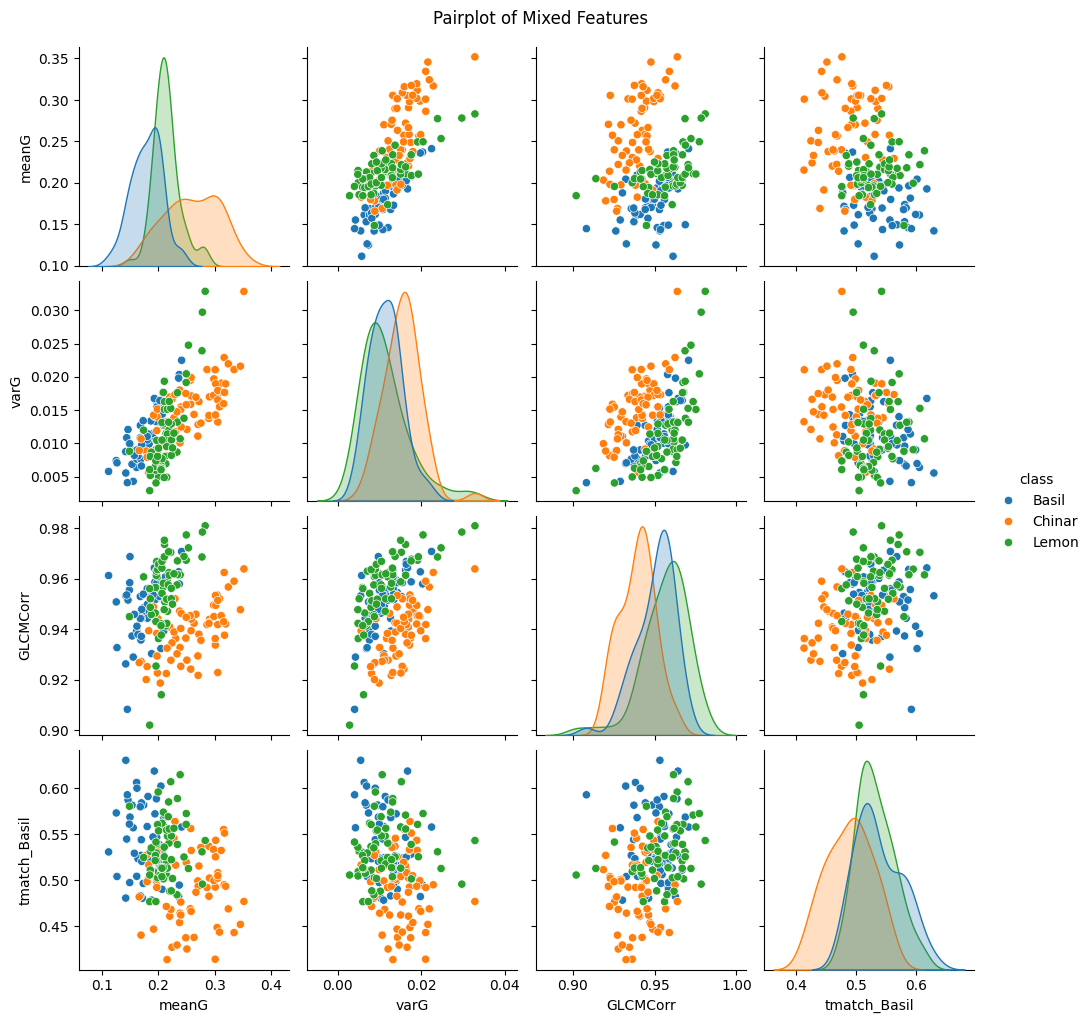

In [7]:
#For pairplots, only a single GLCM correlation feature was used to reduce the total amount of features.
data_list = []
classes = ["Basil", "Chinar", "Lemon"]
for label in classes:
    for imgFeat in featuresDict[label]:
        # Create a flat dictionary for the image
        flatFeat = {
            "class": label,
            "meanR": imgFeat["meanR"],
            "meanG": imgFeat["meanG"],
            "meanB": imgFeat["meanB"],
            "varR": imgFeat["varR"],
            "varG": imgFeat["varG"],
            "varB": imgFeat["varB"],
            "tmatch_Basil": imgFeat["tmatchBasil"],
            "tmatch_Lemon": imgFeat["tmatchLemon"],
            "tmatch_Chinar": imgFeat["tmatchChinar"],
            # Just take one GLCM feature as taking all 9 would be way too big for the pairplot
            "GLCMCorr": imgFeat["correlation"][0, 0] 
        }
        data_list.append(flatFeat)

df = pd.DataFrame(data_list)    #Turn features into a dataframe to be able to use better in seaborn's pairplot function

#Creating the pairplots

# Pairplot 1: Between first order features
sns.pairplot(df, vars=['meanR', 'meanG', 'meanB', 'varR', 'varG', 'varB'], hue='class')
plt.suptitle('Pairplot of First Order Features', y=1.02)
plt.show()

# Pairplot 2: Between template matching features
sns.pairplot(df, vars=['tmatch_Basil', 'tmatch_Lemon', 'tmatch_Chinar'], hue='class')
plt.suptitle('Pairplot of Template Matching Features', y=1.02)
plt.show()

# Pairplot 3: Mixed pairplot, compares some features from both first order, GLCM and template matching features
sns.pairplot(df, vars=['meanG', 'varG', 'GLCMCorr', 'tmatch_Basil'], hue='class')
plt.suptitle('Pairplot of Mixed Features', y=1.02)
plt.show()

### Histograms

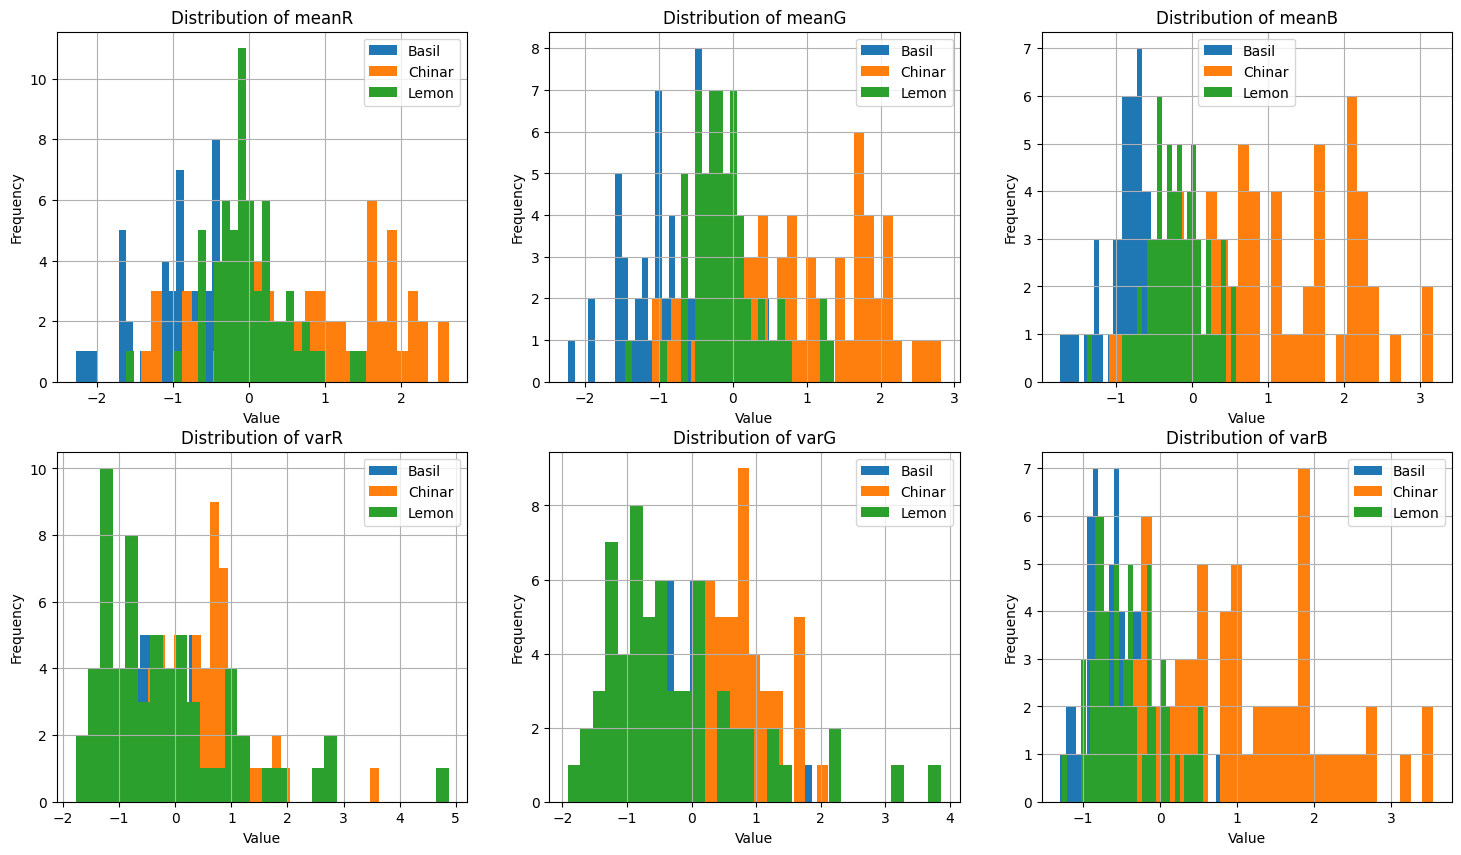

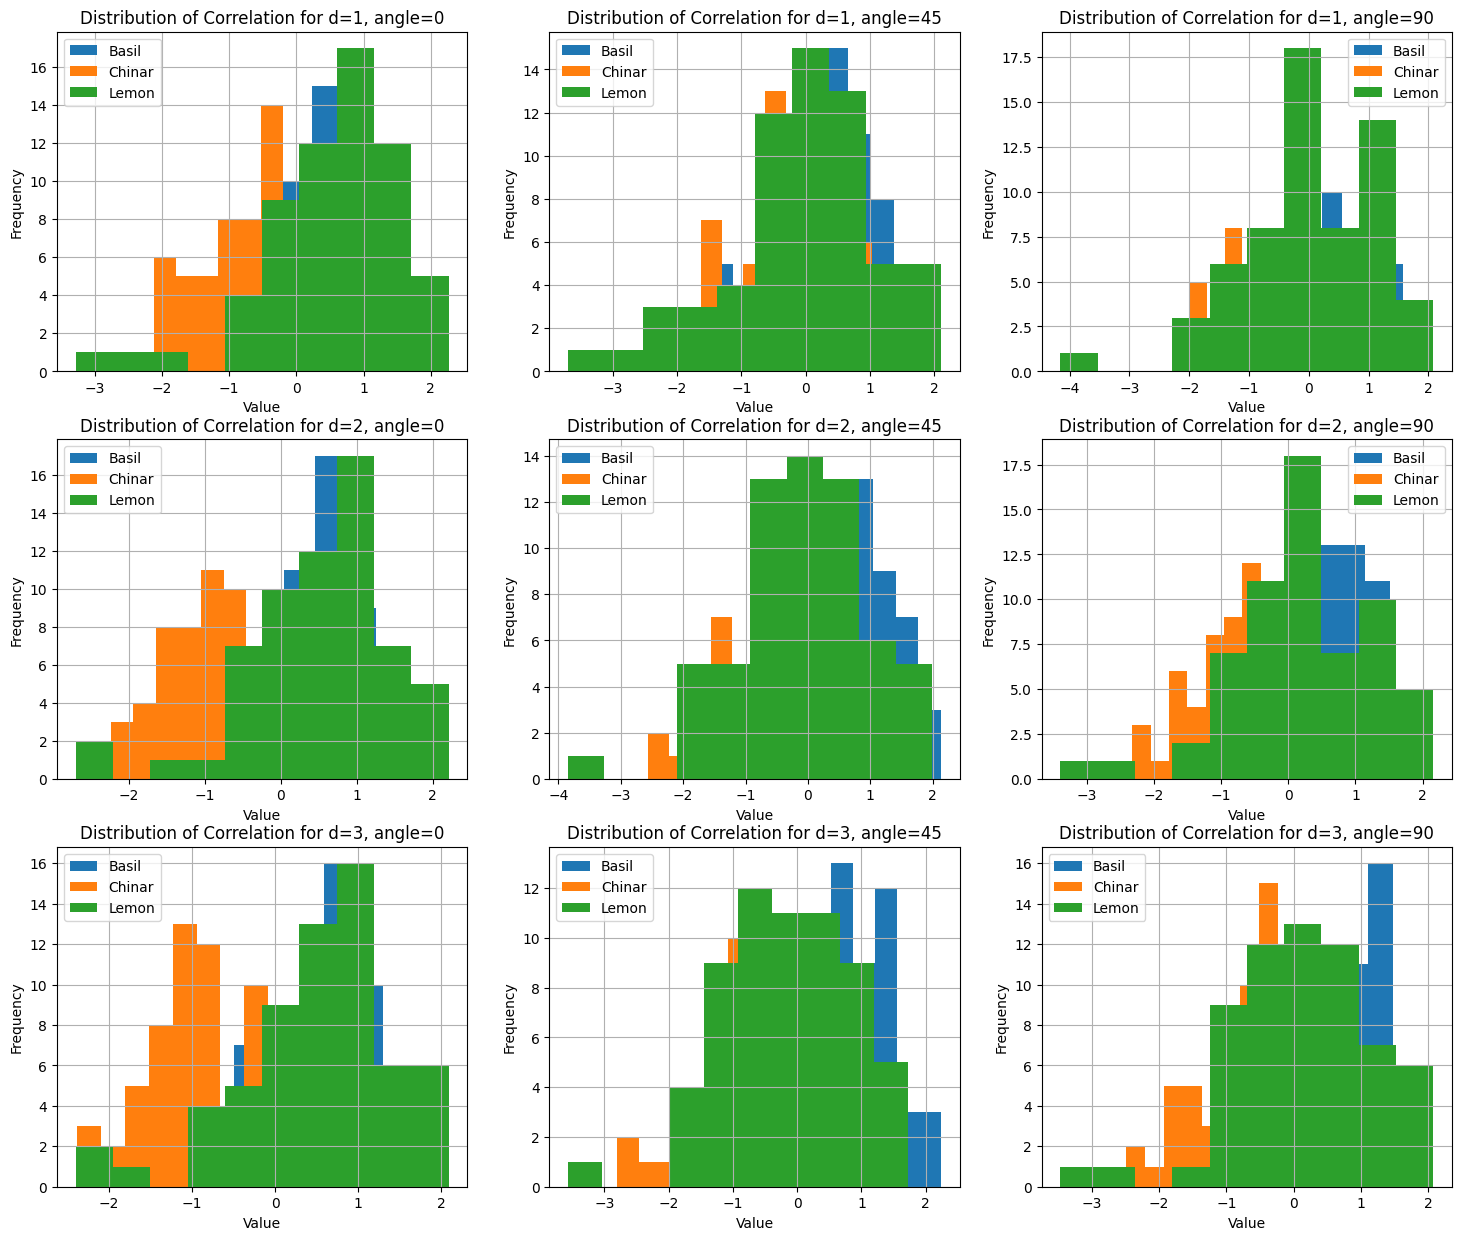

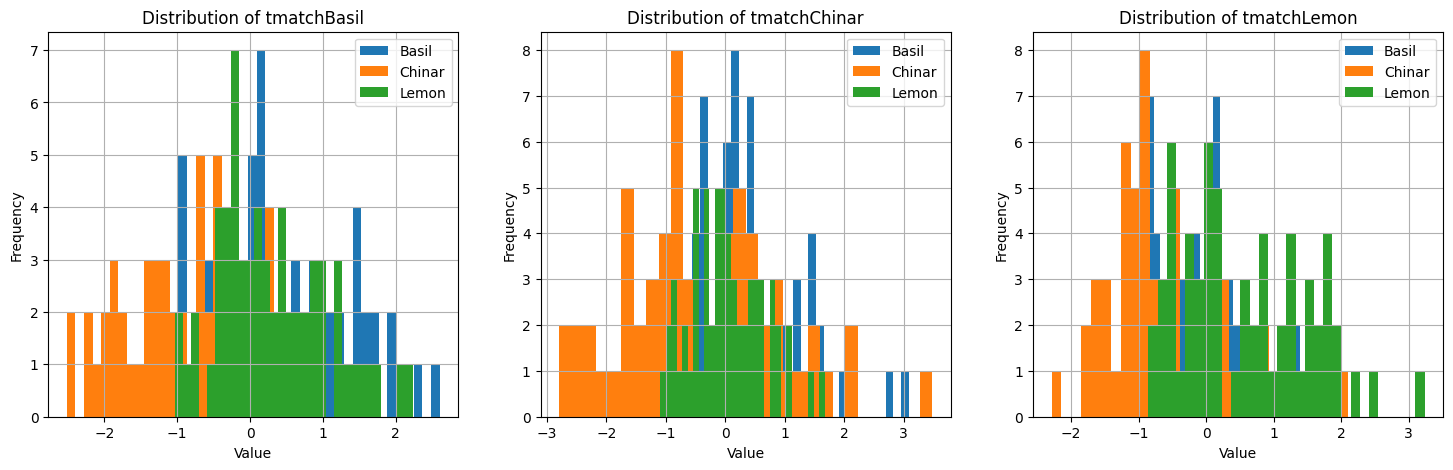

In [8]:
featureNames = ['meanR', 'meanG', 'meanB', 'varR', 'varG', 'varB',"tmatchBasil", "tmatchChinar", "tmatchLemon"]
classes = list(featuresDict.keys())   #Classes in dataset
standarizedfeaturesDict = dict()    #A dictionary that contains seperate dictionaries which contains np arrays for each feature
for className in classes:
    standarizedfeaturesDict[className] = dict()

#Here, we standardize all the first order and template matching features
for feature in featureNames:
    features = extractFeature(featuresDict, feature)
    #Calculate means and std devs of each feature
    mean = np.mean(features)
    stdDev = np.std(features)
    for className in classes:   #Normalize each value for each class
        featuresClassSpecific = extractFeature(featuresDict, feature, className)
        standardized = (featuresClassSpecific-mean)/stdDev
        standarizedfeaturesDict[className][feature] = standardized

#Standardizing the GLCM features

#Get all correlation feature matrices
allCorrMatrix = list()
for className in classes:
    for imgFeatures in featuresDict[className]: #Iterate through each image
        corrMatrix = imgFeatures["correlation"]
        allCorrMatrix.append(corrMatrix)
allCorrMatrix = np.array(allCorrMatrix)
#Calculate mean and variance for each distance and angle
means = np.mean(allCorrMatrix, axis=0)   
stdDevs  = np.std(allCorrMatrix, axis=0)    

#Normalize the correlation features for each angle and distance
for className in classes:
    temp = list()
    for imgFeatures in featuresDict[className]: #Iterate through each image
        corrMatrix = imgFeatures["correlation"]
        standardized = (corrMatrix-means)/stdDevs
        temp.append(standardized)
    temp = np.array(temp)
    standarizedfeaturesDict[className]["correlation"] = temp



#Plots the features
#Create the figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
#Create sub-plots
for idx in range(len(featureNames)-3):    #Go thru each feature
    feature = featureNames[idx]
    ax = axes[idx]
    for classType, vals in standarizedfeaturesDict.items():   #Go through each class type
        featureList = vals[feature]    #Extract this feature's values as a list
        ax.hist(featureList, bins=30, label=classType)
        ax.set_xlabel('Value')
        ax.set_ylabel('Frequency')
        ax.set_title(f'Distribution of {feature}')
        ax.legend()
        ax.grid()

#Plot the GLCM Features
fig, axes = plt.subplots(3, 3, figsize=(18, 15))

for distance in distancesGLCM:
    distIdx = distancesGLCM.index(distance)
    for angle in anglesGLCM:
        angleIdx = anglesGLCM.index(angle)
        for className in classes:
            corrList = list()
            ax = axes[distIdx][angleIdx]
            for corr in standarizedfeaturesDict[className]["correlation"]:
                corrList.append(corr[distIdx][angleIdx])
            ax.hist(corrList,label=className)
            ax.set_xlabel('Value')
            ax.set_ylabel('Frequency')
            ax.set_title(f"Distribution of Correlation for d={distance}, angle={angle}")
            ax.legend()
            ax.grid()

temp_features = ["tmatchBasil", "tmatchChinar", "tmatchLemon"]
fig, axes = plt.subplots(1,3, figsize= (18,5))
axes = axes.flatten()
#Create sub-plots
for idx in range(3):    #Go thru each template matching feature
    feature = temp_features[idx]
    ax = axes[idx]
    for classType, vals in standarizedfeaturesDict.items():   #Go through each class type
        featureList = vals[feature]    #Extract this feature's values as a list
        ax.hist(featureList, bins=30, label=classType)
        ax.set_xlabel('Value')
        ax.set_ylabel('Frequency')
        ax.set_title(f'Distribution of {feature}')
        ax.legend()
        ax.grid()

### PCA

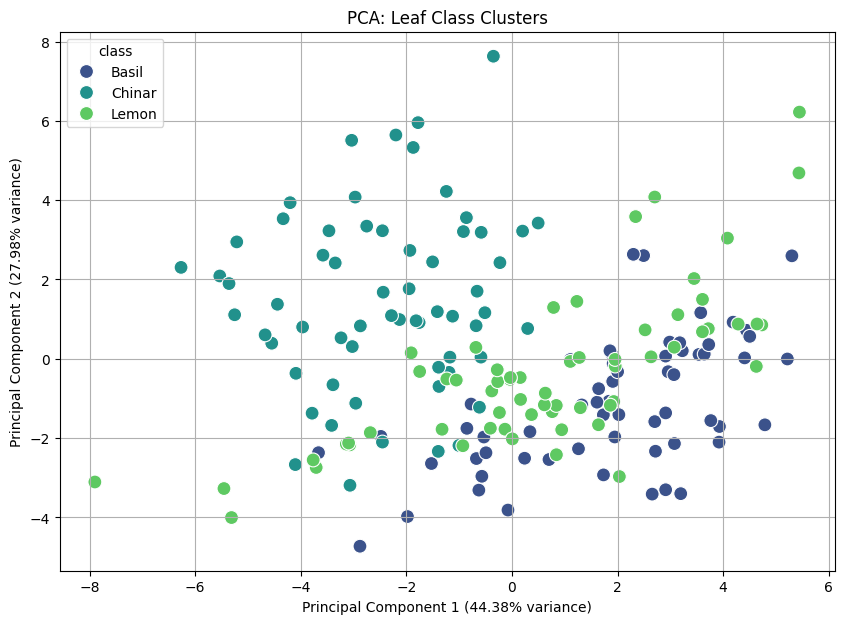

Explained variance ratio: [0.44375178 0.27977564]
Total variance explained by 2 components: 72.35%


In [9]:
allDfs = [] #A dataframe to save all the features into
for label in classes:
    class_dict = standarizedfeaturesDict[label]

    # A new dictionary of standardized features to isolate only 1 GLCM feature
    cleanDict = {}
    for key, val in class_dict.items():
        arr = np.array(val)
        if key == "correlation":    
            # Extract all GLCM correlation features for each distance and angle combination
            for distIdx, dist in enumerate(distancesGLCM):
                for angleIdx, angle in enumerate(anglesGLCM):
                    cleanDict[f"GLCMCorr_d{dist}_a{angle}"] = arr[:, distIdx, angleIdx]
        else:
            cleanDict[key] = arr

    class_df = pd.DataFrame(cleanDict)  #Create a df for the class
    class_df['class'] = label   #Add a column for class name
    allDfs.append(class_df) #Add class df to overall df

dfStandardized = pd.concat(allDfs, ignore_index=True)   #Merge all dfs into 1 df

#Drop the class column from the df
X = dfStandardized.drop(columns=['class'])
yLabels = dfStandardized['class']

#Perform PCA by reducing to 2 components
pca = PCA(n_components=2)
pcaResults = pca.fit_transform(X)

#Add the class column back
dfPCA = pd.DataFrame(data=pcaResults, columns=['PC1', 'PC2'])
dfPCA['class'] = yLabels.values

plt.figure(figsize=(10, 7))
sns.scatterplot(data=dfPCA, x='PC1', y='PC2', hue='class', palette='viridis', s=100)
plt.title('PCA: Leaf Class Clusters')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.grid(True)
plt.show()

print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained by 2 components: {sum(pca.explained_variance_ratio_):.2%}")

# Build classifiers and select the best hyperparameters with cross validation

Perform model selection using Stratified K-Fold Cross Validation and GridSearchCV.<br>
<br>

**Ridge Classifier (1 p)**

Regularization strength:
alpha = [0.001, 0.01, 0.1, 1.0]<br>
<br>

**Random Forest (1 p)**

n_estimators from 100 to 300 (step size 50)

max_features = ['sqrt', 'log2', None]

Use of bootstrap sampling

Report feature importance for each feature.
Which features are the most important?
Does this match your earlier observations? (1 p)<br>
<br>

**MLP (1 p)**

One hidden layer

Number of neurons: 15–40 (step size 5)

Activation functions: tanh, ReLU

Solvers: SGD, Adam

Validation fraction: 0.1, 0.3

L2 regularization strength: alpha = [0.01, 0.1, 1]<br>
<br>

**For each classifier:**

Report the selected hyperparameters

Report accuracy values for tested combinations

### Importing Required Libraries For Model Training

In [10]:
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

### Setting Up Cross-Validation and Features and Labels to Be Used Later

In [11]:
cv = StratifiedKFold(shuffle=True)  #Use stratified K Fold with 5 splits(default) and enable shuffling
#Extract feature names and features as input to model and as class labels
X = dfStandardized.drop(columns=['class']).values
features = dfStandardized.drop(columns=['class']).columns.tolist()    #Get the feature names
Y = dfStandardized['class'].values

### Ridge Classifier (Linear Regression)

In [32]:
alphaGrid = {"alpha": [0.001, 0.01, 0.1, 1]}    #The grid of parameters to try
ridgeSearch = GridSearchCV(estimator=RidgeClassifier(), param_grid=alphaGrid, cv=cv)    #Create the grid search object with given parameter values and cv method
ridgeSearch.fit(X=X,y=Y)    #Train the model on the extracted data and labels

print(f"Best alpha value: {ridgeSearch.best_params_}")
print(f"Best validation accuracy: {ridgeSearch.best_score_:.4f}")

print(f"The mean accuracies across all folds for each alpha parameter")
results_df = pd.DataFrame(ridgeSearch.cv_results_).sort_values(by="mean_test_score", ascending=False).reset_index(drop=True)
results_df[['param_alpha', 'mean_test_score']]


Best alpha value: {'alpha': 0.01}
Best validation accuracy: 0.9078
The mean accuracies across all folds for each alpha parameter


,param_alpha,mean_test_score
0,0.010,0.907808
1,0.001,0.907658
2,0.100,0.902252
3,1.000,0.896697


### Random Forest

In [31]:
rfGrid = {
    "n_estimators": [100, 150, 200, 250, 300],
    "max_features": ["sqrt", "log2", None],
    "bootstrap" : [True]
}
forestSearch = GridSearchCV(estimator=RandomForestClassifier(), param_grid=rfGrid)  #Create the grid search object with given parameter values and cv method

forestSearch.fit(X,Y)   #Train the model on the extracted data and labels

print(f"Best n_estimators value: {forestSearch.best_params_["n_estimators"]}")
print(f"Best max_features value: {forestSearch.best_params_["max_features"]}")
print(f"Best mean accuracy: {forestSearch.best_score_:.4f}")

resultsDf = pd.DataFrame(forestSearch.cv_results_).sort_values(by="mean_test_score", ascending=False).reset_index(drop=True)
resultsDf[["param_n_estimators", "param_max_features", "mean_test_score"]].head(len(resultsDf))


Best n_estimators value: 150
Best max_features value: sqrt
Best mean accuracy: 0.8914


,param_n_estimators,param_max_features,mean_test_score
0,150,sqrt,0.891441
1,100,sqrt,0.880631
2,300,log2,0.880631
3,100,log2,0.880631
4,200,sqrt,0.875225
5,150,log2,0.869820
6,300,sqrt,0.869820
7,250,log2,0.869820
8,200,log2,0.869820
9,250,sqrt,0.853453


#### Determining Feature Importance

In [14]:
bestRF = forestSearch.best_estimator_

importances = bestRF.feature_importances_

importancesDf = pd.DataFrame({
    "Feature":features,
    "Importance":importances
})
importancesDf = importancesDf.sort_values(by="Importance", ascending=False).reset_index(drop=True)

importancesDf.head(len(importancesDf))


,Feature,Importance
0,meanB,0.158071
1,meanR,0.104308
2,meanG,0.096526
3,varB,0.093305
4,GLCMCorr_d3_a0,0.084990
5,GLCMCorr_d2_a90,0.064255
6,GLCMCorr_d2_a0,0.047897
7,tmatchLemon,0.046799
8,GLCMCorr_d1_a0,0.045370
9,GLCMCorr_d3_a90,0.043519


### Explain similarity with feature analysis here

### MLP

In [15]:
#Create the mlp parameter search grid
mlpGrid = {
    "hidden_layer_sizes": [i for i in range(15,45,5)],
    "activation": ['tanh', 'relu'],
    "solver": ["sgd", "adam"],
    "validation_fraction": [0.1, 0.3],
    "alpha": [0.01, 0.1, 1]
}

mlpSearch = GridSearchCV(estimator=MLPClassifier(max_iter=10000),param_grid=mlpGrid, cv=cv)    #Create the mlp grid search object
mlpSearch.fit(X,Y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",MLPClassifier(max_iter=10000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'activation': ['tanh', 'relu'], 'alpha': [0.01, 0.1, ...], 'hidden_layer_sizes': [15, 20, ...], 'solver': ['sgd', 'adam'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computati

In [35]:
print(f"Best number of neurons value: {mlpSearch.best_params_["hidden_layer_sizes"]}")
print(f"Best alpha (Regularization Strength) value: {mlpSearch.best_params_["alpha"]}")
print(f"Best validation fraction value: {mlpSearch.best_params_["validation_fraction"]}")
print(f"Best solver: {mlpSearch.best_params_["solver"]}")
print(f"Best activation function: {mlpSearch.best_params_["activation"]}")
print(f"Best mean accuracy: {mlpSearch.best_score_:.4f}")


resultsDf = pd.DataFrame(mlpSearch.cv_results_).sort_values(by="mean_test_score", ascending=False).reset_index(drop=True)
resultsDf[["param_hidden_layer_sizes", "param_alpha", "param_validation_fraction", "mean_test_score"]].head(len(resultsDf))

Best number of neurons value: 30
Best alpha (Regularization Strength) value: 0.01
Best validation fraction value: 0.3
Best solver: adam
Best activation function: relu
Best mean accuracy: 0.9294


,param_hidden_layer_sizes,param_alpha,param_validation_fraction,mean_test_score
0,30,0.01,0.3,0.929429
1,35,0.01,0.3,0.928979
2,40,0.10,0.3,0.923874
3,40,0.01,0.1,0.923724
4,35,0.01,0.1,0.923724
...,...,...,...,...
139,40,0.10,0.1,0.863363
140,30,0.01,0.1,0.858108
141,20,0.01,0.3,0.858108
142,25,0.10,0.3,0.857958


# Estimate the performance of the models with nested cross-validation

Estimate model performance using nested cross-validation.

Inner loop: 5-fold Stratified K-Fold (model selection)

Outer loop: 4-fold Stratified K-Fold (performance estimation)<br>
<br>

For each classifier:

Ridge Classifier **(1 p)**

Random Forest **(1 p)**

MLP **(1 p)**<br>
<br>

Report:

Selected hyperparameters

Accuracy value of the best model

Confusion matrix

Mean accuracy of the outer folds
Explain what this value represents

# Discussion (2 p)

Discuss your results, for example:

Which classifier performed best and why?

What are the limitations of the approach?

How could the results be improved?